# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy test : 0.9722
F1 macro test : 0.9710
Accuracy CV   : 0.9791

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



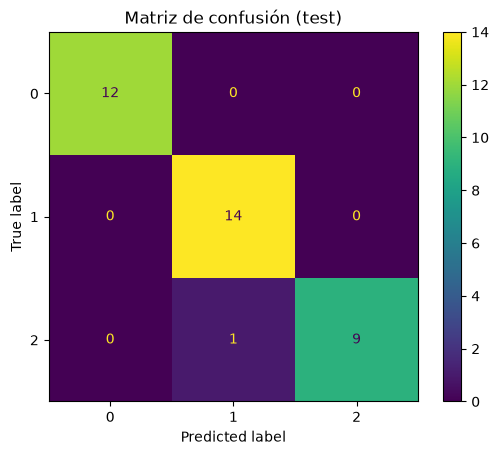

In [4]:
# Predicciones del modelo campeón sobre test (solo una vez)
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test : {test_accuracy:.4f}")
print(f"F1 macro test : {test_f1_macro:.4f}")
print(f"Accuracy CV   : {training_metadata['cv_accuracy_mean']:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Matriz de confusión (test)")
plt.show()

**Análisis:**

> - **Coherencia con CV:** sí. En test el modelo obtiene accuracy ≈ **0.972** y F1 macro ≈ **0.971**, muy cerca del ≈ 0.979 de la validación cruzada. La pequeña diferencia es normal porque el test tiene solo 36 muestras (un error cambia el accuracy en ~2.8 puntos).
> - **Clases confundidas:** solo hubo **un error**: un vino de la **clase 2 se predijo como clase 1** (recall de la clase 2 = 0.90). La clase 0 se clasificó perfectamente.
> - **Sobreajuste:** no hay evidencia importante. Aunque el accuracy de entrenamiento es 1.0, el desempeño en test se mantiene alto y parecido al de CV, así que el modelo generaliza bien.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    # Valida el esquema y devuelve las predicciones del pipeline.
    # 1) Verificamos que no falte ninguna columna
    missing = [col for col in feature_columns if col not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas: {missing}")

    # 2) Ordenamos las columnas igual que en entrenamiento (y quitamos extras)
    X = records[feature_columns]

    # 3) Predicción y probabilidades de cada clase
    result = pd.DataFrame(index=records.index)
    result["prediction"] = model.predict(X)
    probabilities = model.predict_proba(X)
    for i, clase in enumerate(model.classes_):
        result[f"proba_{clase}"] = probabilities[:, i]
    return result

## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_predictions

,prediction,proba_0,proba_1,proba_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


## 5. Reporte final

In [7]:
# Guardamos las métricas finales
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(test_accuracy),
    "f1_macro": float(test_f1_macro),
}
with open(REPORTS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

test_metrics

{'model': 'logistic_regression',
 'accuracy': 0.9722222222222222,
 'f1_macro': 0.9709618874773139}

In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.



## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.